In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
#upload data intended for use
df=pd.read_csv('/content/Filtered maternity Register.csv')

In [ ]:
headers = df.columns.values.tolist()
print(headers)

['start', 'end', 'start-geopoint', '_start-geopoint_latitude', '_start-geopoint_longitude', '_start-geopoint_altitude', '_start-geopoint_precision', 'County', 'Sub County (Kisumu)', 'Sub County (Siaya)', 'Facility Name (Nyando)', 'Facility Name (Seme)', 'Facility Name (Nyakach)', 'Facility Name (Kisumu Central)/Kisumu County Referral Hospital - #13704', 'Facility Name (Kisumu West)', 'Facility Name (Kisumu East)', 'Facility Name (Alego-Usonga)', 'Facility Name (Gem)', 'Facility Name (Ugunja)', 'Facility Type', 'Date of Data Extraction', 'Extracted by', 'Admission date', 'Admission  no.', 'DoB/age', 'Sub-county', 'Village/estate', 'Marital Status', 'Parity', 'Gravidae', 'ANC visits', 'LMP', 'EDD', 'Diagnosis', 'Diagnosis Conclusion (Referred or Not/False  Labour)', 'Labour', 'Delivery date', 'Time of delivery', 'Gestation', 'Delivery mode', 'No. of babies', 'Mother status', 'Mother died', 'Complications', 'Babies born', 'Birth outcome 1', 'Birth weight 1', 'Baby’s sex 1', 'Birth outcome

In [ ]:
df.describe()

,_start-geopoint_latitude,_start-geopoint_longitude,_start-geopoint_altitude,_start-geopoint_precision,Sub County (Siaya),Facility Name (Nyando),Facility Name (Seme),Facility Name (Nyakach),Facility Name (Kisumu Central)/Kisumu County Referral Hospital - #13704,Facility Name (Kisumu East),...,Discharge baby 5,Village/estate. (Use the code 'MD' for Missing data or 'NIR' for Not in the register as a response to this question if needed.),Parity (Use the code 'MD' for Missing data or 'NIR' for Not in the register as a response to this question if needed.),Diagnosis (Detailed),Remarks,_id,_validation_status,_notes,_tags,_index
count,4799.000000,4799.000000,4799.000000,4799.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,5.993000e+03,0.0,0.0,0.0,5993.000000
mean,-0.060132,34.640811,1161.592174,285.673453,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.729180e+08,NaN,NaN,NaN,29375.963124
std,0.035052,0.032143,434.606170,775.228922,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.002680e+07,NaN,NaN,NaN,9318.034685
min,-0.115462,34.603186,0.000000,1.050000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.559491e+08,NaN,NaN,NaN,8633.000000
25%,-0.114955,34.609559,1221.000000,3.050000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.637380e+08,NaN,NaN,NaN,21874.000000
50%,-0.038012,34.638314,1349.599976,16.118000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.730816e+08,NaN,NaN,NaN,30191.000000
75%,-0.037897,34.638386,1350.099976,25.083000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.797377e+08,NaN,NaN,NaN,36162.000000
max,-0.018568,34.772521,1784.600000,4800.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.956357e+08,NaN,NaN,NaN,47882.000000


In [ ]:
#Retain only columns i will need and drop the rest
df_select=df[['Facility Name (Kisumu West)','Admission  no.','Parity','Gravidae','Babies born','Birth weight 1','Birth weight 2','Birth weight 3']]
print(df_select)


        Facility Name (Kisumu West) Admission  no. Parity Gravidae  \
0     Chulaimbo Sub County Hospital           1234    0+1        2   
1     Chulaimbo Sub County Hospital            637    5+0        6   
2     Chulaimbo Sub County Hospital            644    0+0        1   
3     Chulaimbo Sub County Hospital            646    2+0        3   
4     Chulaimbo Sub County Hospital            645    0+0        1   
...                             ...            ...    ...      ...   
5988  Chulaimbo Sub County Hospital         288/20    1+0        2   
5989  Chulaimbo Sub County Hospital         289/20    2+0        3   
5990  Chulaimbo Sub County Hospital         265/20    0+0        1   
5991  Chulaimbo Sub County Hospital         290/20    3+0        4   
5992  Chulaimbo Sub County Hospital         291/20    1+1        3   

      Babies born  Birth weight 1  Birth weight 2  Birth weight 3  
0               2             2.5             4.5             NaN  
1               1      

In [ ]:
#total number of missing gravidae entries
df_select['Gravidae'].isna().sum()

np.int64(0)

In [ ]:
#drop rows in gravidae with missing values
df_select = df_select.dropna(subset=['Gravidae'])

In [ ]:
#Handling missing values in Parity
df_select['Parity'].isna().sum()

np.int64(0)

In [ ]:
df_select = df_select.dropna(subset=['Parity'])

In [ ]:
# Ensuring all gravidae are integers
#1st transform to numeric
df_select["Gravidae"] = pd.to_numeric(df_select["Gravidae"], errors="coerce")

# Remove rows where Gravidae could not be converted to a number
df_select = df_select.dropna(subset=["Gravidae"])

# Convert to integer
df_select["Gravidae"] = df_select["Gravidae"].astype(int)

SPLITTING THE PARITY VARIABLE

In [ ]:
#Converting parity to text and removing the spaces
parity = df_select["Parity"].astype("string").str.strip()

#Spliting parity at the plus sign
parity_parts = parity.str.split("+", n=1, expand=True, regex=False)

#Creating two numeric columns
df_select["Parity_First"] = pd.to_numeric(
    parity_parts[0], errors="coerce"
)

df_select["Parity_Second"] = pd.to_numeric(
    parity_parts[1], errors="coerce"
)

#Confirmation of split
print(df_select[[
    "Parity",
    "Parity_First",
    "Parity_Second"
]].head())

  Parity  Parity_First  Parity_Second
0    0+1             0            1.0
1    5+0             5            0.0
2    0+0             0            0.0
3    2+0             2            0.0
4    0+0             0            0.0


GETTING RID OF ROWS WITH ROWS WITH MISSING PARITY VALUES  

In [ ]:
#checking fo missing values in parity
print(df_select[["Parity_First", "Parity_Second"]].isna().sum())

Parity_First      8
Parity_Second    20
dtype: int64


In [ ]:
#dropping rows missing first parity
df_select=df_select.dropna(subset=['Parity_First'])

In [ ]:
##dropping rows missing second parity
df_select=df_select.dropna(subset=['Parity_Second'])

In [ ]:
print(df_select[["Parity_First", "Parity_Second"]].isna().sum())

Parity_First     0
Parity_Second    0
dtype: int64


In [ ]:
#drop rows with missing values for babies born
df_select=df_select.dropna(subset=['Babies born'])

In [ ]:
#get total number of missing entries in bby born column
df_select['Babies born'].isna().sum()

np.int64(0)

In [ ]:
df_select['Birth weight 1'].isna().sum()

np.int64(0)

In [ ]:
#detecting and removing outliers
Q1 = df['Birth weight 1'].quantile(0.25)
Q3 = df['Birth weight 1'].quantile(0.75)
IQR = Q3 - Q1

#Define acceptable boundaries

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out the outliers
df_cleaned= df_select[
    (df_select['Birth weight 1'] >= lower_bound) &
    (df_select['Birth weight 1'] <= upper_bound)
]

In [ ]:
df_cleaned.describe()

,Gravidae,Babies born,Birth weight 1,Birth weight 2,Birth weight 3,Parity_First,Parity_Second
count,5561.000000,5561.000000,5561.000000,40.000000,1.0,5561.0,5561.0
mean,2.645567,1.007373,3188.415753,2361.400000,98.0,1.568783,0.087035
std,1.663641,0.087632,437.395363,695.763915,NaN,1.531911,0.360823
min,1.000000,1.000000,2000.000000,98.000000,98.0,0.0,0.0
25%,1.000000,1.000000,2950.000000,2100.000000,98.0,0.0,0.0
50%,2.000000,1.000000,3200.000000,2355.000000,98.0,1.0,0.0
75%,4.000000,1.000000,3500.000000,2700.000000,98.0,3.0,0.0
max,33.000000,3.000000,4400.000000,3600.000000,98.0,9.0,9.0


In [ ]:
#list of all columns contained in cleaned dataframe
print(df_cleaned.columns.tolist())

['Facility Name (Kisumu West)', 'Admission  no.', 'Parity', 'Gravidae', 'Babies born', 'Birth weight 1', 'Birth weight 2', 'Birth weight 3', 'Parity_First', 'Parity_Second']


In [ ]:
df_weight = df_cleaned.melt(
    id_vars=['Admission  no.','Parity_First','Parity_Second','Gravidae','Babies born'],
    value_vars=['Birth weight 1', 'Birth weight 2', 'Birth weight 3'],
    var_name='Baby_number',
    value_name='Birth_weight'
)

#Get rid of outliers in the new birth eight column birth weights

Q1 = df_weight['Birth_weight'].quantile(0.25)
Q3 = df_weight['Birth_weight'].quantile(0.75)
IQR = Q3 - Q1

#Define acceptable boundaries

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out the outliers
df_filtered= df_weight[
    (df_weight['Birth_weight'] >= lower_bound) &
    (df_weight['Birth_weight'] <= upper_bound)
]

print(df_filtered)

      Admission  no.  Parity_First  Parity_Second  Gravidae  Babies born  \
0                637             5            0.0         6            1   
1                644             0            0.0         1            1   
2                646             2            0.0         3            1   
3                645             0            0.0         1            1   
4                639             3            0.0         4            1   
...              ...           ...            ...       ...          ...   
10847            612             3            0.0         4            2   
10849            619             5            0.0         6            2   
10861            636             3            0.0         4            2   
11086         255/20             1            0.0         2            2   
11098         271/20             2            0.0         3            2   

          Baby_number  Birth_weight  
0      Birth weight 1        3500.0  
1      Birt

In [ ]:
#reshape birth weight columns into a single column
df_weight = df_cleaned.melt(
    id_vars=['Admission  no.','Gravidae','Babies born','Parity_First','Parity_Second'],
    value_vars=['Birth weight 1', 'Birth weight 2', 'Birth weight 3'],
    var_name='Baby_number',
    value_name='Birth_weight'
)

print(df_weight)

      Admission  no.  Gravidae  Babies born  Parity_First  Parity_Second  \
0                637         6            1             5            0.0   
1                644         1            1             0            0.0   
2                646         3            1             2            0.0   
3                645         1            1             0            0.0   
4                639         4            1             3            0.0   
...              ...       ...          ...           ...            ...   
16678         288/20         2            1             1            0.0   
16679         289/20         3            1             2            0.0   
16680         265/20         1            1             0            0.0   
16681         290/20         4            1             3            0.0   
16682         291/20         3            1             1            1.0   

          Baby_number  Birth_weight  
0      Birth weight 1        3500.0  
1      Birt

In [ ]:
df_filtered.describe()

,Parity_First,Parity_Second,Gravidae,Babies born,Birth_weight,Low_Birth_Weight
count,5596.0,5596.0,5596.000000,5596.000000,5596.000000,5596.000000
mean,1.571837,0.086669,2.648499,1.013581,3184.388849,0.051644
std,1.532497,0.359964,1.663120,0.117288,440.240575,0.221327
min,0.0,0.0,1.000000,1.000000,2000.000000,0.000000
25%,0.0,0.0,1.000000,1.000000,2900.000000,0.000000
50%,1.0,0.0,2.000000,1.000000,3200.000000,0.000000
75%,3.0,0.0,4.000000,1.000000,3500.000000,0.000000
max,9.0,9.0,33.000000,3.000000,4400.000000,1.000000


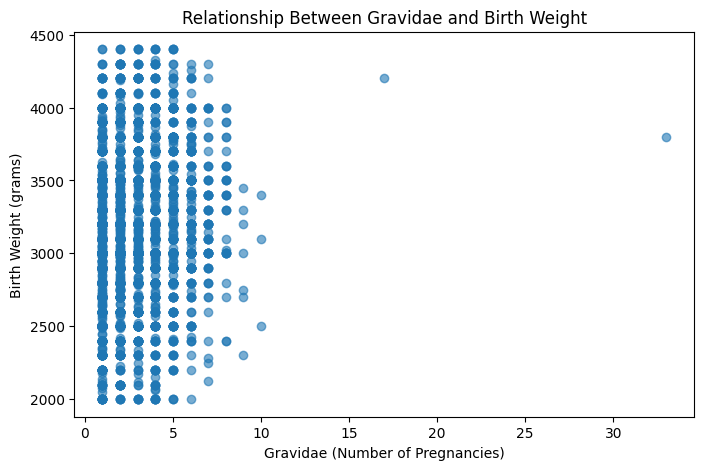

<Figure size 2000x500 with 0 Axes>

In [ ]:
#relationship btn gravedae and birth weight
import matplotlib.pyplot as plt
import seaborn as sns


# Scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(df_filtered["Gravidae"], df_filtered["Birth_weight"], alpha=0.6)

plt.xlabel("Gravidae (Number of Pregnancies)")
plt.ylabel("Birth Weight (grams)")
plt.title("Relationship Between Gravidae and Birth Weight")

plt.figure(figsize=(20, 5))

plt.show()

PEARSON CORRELATION OF GRAVIDAE AND PARITY TO BIRTH WEIGHT

In [ ]:
import pandas as pd
from scipy.stats import pearsonr

# Convert columns to numeric
columns = [
    "Gravidae",
    "Parity_First",
    "Parity_Second",
    "Birth_weight"
]

for col in columns:
    df_filtered[col] = pd.to_numeric(df_filtered[col], errors="coerce")

# Variables to correlate with birth weight
predictors = [
    "Gravidae",
    "Parity_First",
    "Parity_Second"
]

for col in predictors:
    data = df_filtered[[col, "Birth_weight"]].dropna()

    # Check whether correlation can be calculated
    if len(data) < 3 or data[col].nunique() < 2:
        print(f"\n{col}: Insufficient data or variation.")
        continue

    r, p = pearsonr(data[col], data["Birth_weight"])

    print(f"\n{col} vs Birth_weight")
    print("Number of observations:", len(data))
    print("Pearson correlation (r):", round(r, 3))
    print("P-value:", round(p, 4))



Gravidae vs Birth_weight
Number of observations: 5596
Pearson correlation (r): 0.132
P-value: 0.0

Parity_First vs Birth_weight
Number of observations: 5596
Pearson correlation (r): 0.136
P-value: 0.0

Parity_Second vs Birth_weight
Number of observations: 5596
Pearson correlation (r): 0.01
P-value: 0.4433


DECISION TREE MODELLING

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
X = df_filtered[["Gravidae","Parity_First","Parity_Second"]]
y = df_filtered["Birth_weight"]

#Splitting into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#Decision tree model creation
model = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

# Training the model
model.fit(X_train, y_train)

# Telling model to make predictions
y_pred = model.predict(X_test)



DECISION TREE EVALUATION

In [ ]:
#evaluating the decision tree model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)

Mean Absolute Error (MAE): 363.1785325046371
Root Mean Squared Error (RMSE): 456.93127278472423
R² Score: 0.021533046211642315


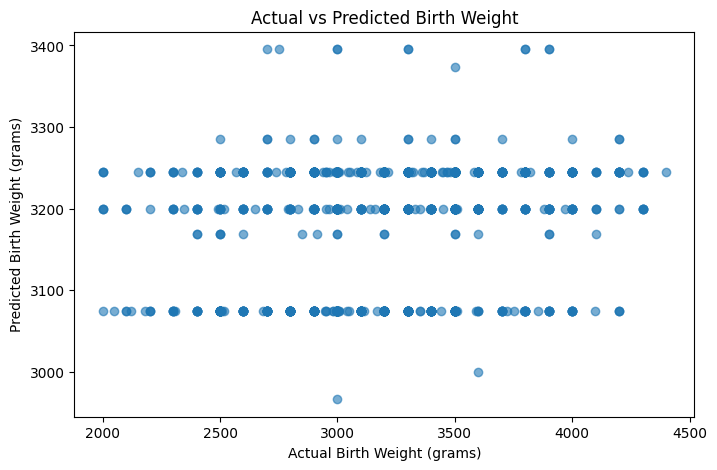

In [ ]:
#comparing the actual birth weights with the model's predicted birth weights
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual Birth Weight (grams)")
plt.ylabel("Predicted Birth Weight (grams)")
plt.title("Actual vs Predicted Birth Weight")

plt.show()

LOW BIRTH WEIGHT

In [ ]:
# Low birth weight is defined as birth weight below 2500 grams
df_filtered["Low_Birth_Weight"] = (
    df_filtered["Birth_weight"] < 2500
).astype(int)

# Check the number of infants in each category
print("Low Birth Weight Distribution:")
print(df_filtered["Low_Birth_Weight"].value_counts())

# Check percentages
print("\nPercentage Distribution:")
print(
    df_filtered["Low_Birth_Weight"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Low Birth Weight Distribution:
Low_Birth_Weight
0    5307
1     289
Name: count, dtype: int64

Percentage Distribution:
Low_Birth_Weight
0    94.84
1     5.16
Name: proportion, dtype: float64


LOGISTIC REGRESSION MODEL

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

model_df = df_filtered[
    ["Gravidae","Parity_First","Parity_Second","Low_Birth_Weight"]
].dropna().copy()

#Converting target to integer

model_df["Low_Birth_Weight"] = (
    model_df["Low_Birth_Weight"].astype(int)
)



In [ ]:
#defination of predictors and targets
X = model_df[["Gravidae","Parity_First","Parity_Second"]]

y = model_df["Low_Birth_Weight"]


In [ ]:
#Creating train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
#Creating and training Logistic Regression
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

# Predict low birth weight
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]


In [ ]:
# 9. Evaluate the model
from sklearn.metrics import roc_auc_score

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Not Low Birth Weight", "Low Birth Weight"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 10. Calculate ROC-AUC, if both classes are in the test set
if y_test.nunique() == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

Accuracy: 0.946

Classification Report:
                      precision    recall  f1-score   support

Not Low Birth Weight       0.95      1.00      0.97      1062
    Low Birth Weight       0.00      0.00      0.00        58

            accuracy                           0.95      1120
           macro avg       0.47      0.50      0.49      1120
        weighted avg       0.90      0.95      0.92      1120


Confusion Matrix:
[[1060    2]
 [  58    0]]
ROC-AUC: 0.529


In [ ]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Display the results
print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1-score:  {f1:.2%}")

Model Evaluation Results
------------------------
Accuracy:  94.64%
Precision: 0.00%
Recall:    0.00%
F1-score:  0.00%


In [ ]:
# Correlation Analysis

correlation_data = df_filtered[
    ["Gravidae", "Birth_weight"]
]

correlation_matrix = correlation_data.corr()

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,Gravidae,Birth_weight
Gravidae,1.000000,0.131567
Birth_weight,0.131567,1.000000


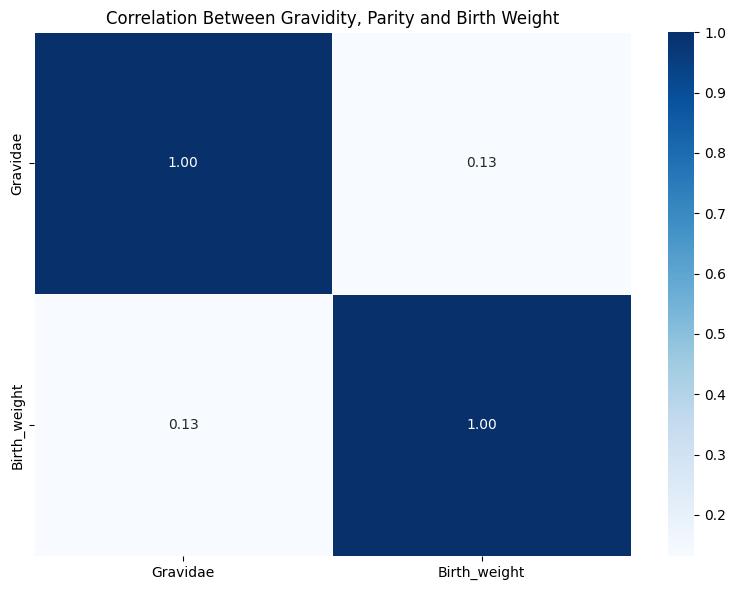

In [ ]:
# Correlation Heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Correlation Between Gravidity, Parity and Birth Weight")
plt.tight_layout()
plt.show()

In [ ]:
# Compare Gravidity by Low Birth Weight

low_birth_weight_summary = df_filtered.groupby(
    "Low_Birth_Weight"
)[["Gravidae"]].agg(
    ["mean", "median", "count"]
)

print("Gravidity by Birth Weight Category:")
display(low_birth_weight_summary)

Gravidity by Birth Weight Category:


Gravidae             
                      mean median count
Low_Birth_Weight                       
0                 2.661391    2.0  5307
1                 2.411765    2.0   289

In [ ]:
# Final Results Summary

results_summary = pd.DataFrame({
    "Analysis": [
        "Gravidae vs Birth Weight",
        "Decision Tree Regression",
        "Logistic Regression"
    ],
    "Result": [
        "r = 0.1331, p < 0.001",
        f"MAE = {mae:.2f}, RMSE = {rmse:.2f}, R² = {r2:.4f}",
        f"Accuracy = {accuracy:.4f}, F1 = {f1:.4f}"
    ]
})
display(results_summary)


,Analysis,Result
0,Gravidae vs Birth Weight,"r = 0.1331, p < 0.001"
1,Decision Tree Regression,"MAE = 363.18, RMSE = 456.93, R² = 0.0215"
2,Logistic Regression,"Accuracy = 0.9464, F1 = 0.0000"


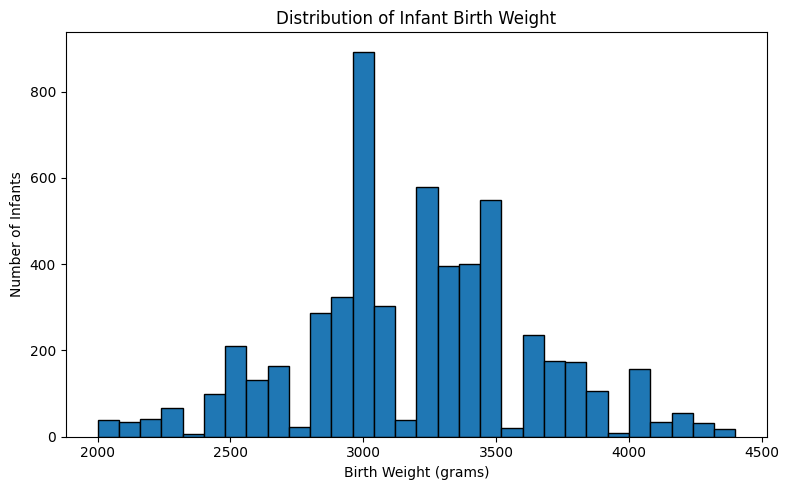

In [ ]:
# Birth Weight Distribution

plt.figure(figsize=(8, 5))

plt.hist(
    df_filtered["Birth_weight"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Birth Weight (grams)")
plt.ylabel("Number of Infants")
plt.title("Distribution of Infant Birth Weight")

plt.tight_layout()
plt.show()

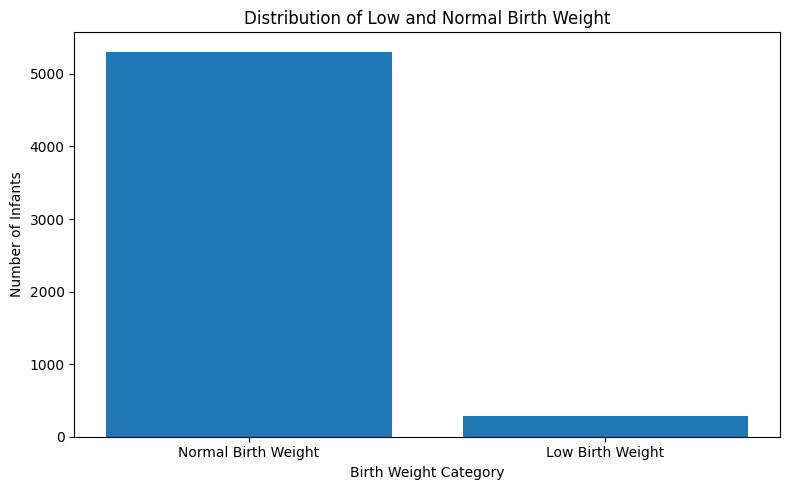

In [ ]:
# Low Birth Weight vs Normal Birth Weight

birth_weight_counts = df_filtered["Low_Birth_Weight"].value_counts().sort_index()

labels = ["Normal Birth Weight", "Low Birth Weight"]

plt.figure(figsize=(8, 5))

plt.bar(labels, birth_weight_counts.values)

plt.xlabel("Birth Weight Category")
plt.ylabel("Number of Infants")
plt.title("Distribution of Low and Normal Birth Weight")

plt.tight_layout()
plt.show()

In [ ]:
!pip install openpyxl

In [ ]:
# Save the filtered dataframe to a CSV file first
df_filtered.to_csv("processed_maternity_data.csv", index=False)

# Download the saved file to your computer
from google.colab import files
files.download("processed_maternity_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>